# GSTools ideal-fit results and fitting-fraction analysis

This notebook reads the `PARAMETERS` extension written by your ideal fitting workflow.
It combines the model/`sigE` comparison from `plot_parameters_modules` with the fraction
inspection and selected-result stage from `fit_fraction_workflow`.

**Place this notebook in the pipeline root and the supplied module in `py_modules/`.**
No `results_comp`, `plot_parameters_utils`, `fit_fraction_latex_tools`, or fitting modules
are required. No fits are rerun and no source FITS files are modified.

Supported names include `stable_alpha1.5_moments_N64_L16_sigE0_L020.fits`, native fits
without a fraction suffix, and `.fits.gz`. Fractions are read from `FITFRAC` first, with
`_L020`–`_L100` as fallback. `0.99` and `1.00` remain distinct. Unlabelled original fits
are **baselines with unknown fraction**, not automatically assigned 0.60.

In [1]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "py_modules"))
import gstools_fit_viz as gv
gv = importlib.reload(gv)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

## 1. Configuration

Defaults follow the current ideal pipeline: `fits_ready/`, three parameters, and
fractions 0.20–0.90 plus 0.99. `None` means all available values. The plotting loops
make separate figures for different `N`, length scale, bin, and seed; they never average
those experiments together. If duplicate realizations lack a seed, filter `source_dir`
or `sample_id` below. Do not infer a seed from a folder name.

Parameter labels are configurable. The default length unit is a **pixel** for your
synthetic `PC = PIX = 1` maps; change it if your maps use another scale.

In [2]:
FITS_DIR = ROOT / "fits_ready" / "tuned"
FIGS_DIR = ROOT / "Imgs" / "fit_results"
TABLES_DIR = ROOT / "results_fit" / "visualization"
RECURSIVE = True
SAVE_FIGURES = True
FIGURE_FORMATS = ("pdf", "png")

ALL_FIT_LIMITS = (0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.99)
COMPARISON_FRACTION = 0.60  # None selects the untagged baseline fits instead.
SELECTED_FIT_LIMITS = (0.40, 0.50, 0.60)
REQUIRE_ALL_SELECTED = True
# Override selection for particular sample_id values, copied from the inventory:
SELECTED_BY_SAMPLE = {}

FILTERS = {
    "grid_size": 256,       # e.g. 64, or (64, 128)
    "length_scale": None,    # e.g. 16
    "spatial_bin": None,     # e.g. 0
    "sigE": (0, 1, 2),
    "model": "gaussian",           # e.g. ("exponential", "stable", "gaussian")
    "alpha": None,           # e.g. 1.5; this excludes non-stable rows with missing ALPHA
    "seed": None,
    "source_dir": None,      # relative subfolder, if needed to separate realizations
    "sample_id": None,
}
SIGE_LEVELS = (0, 1, 2)
#SIGE_LEVELS = (0,)

MODEL_ORDER = None  # Default: exponential, each stable alpha, gaussian.
PARAM_LABELS = {
    "sig2": r"$\sigma_{\mathrm{pos}}^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pixel]",
    "m": r"$m$",
}
PARAM_YLIMS = None  # Example: {"m": (0.5, 2.0)}

REFERENCE_KEYS = {"sig2": "SIG2", "r0": "R0", "m": "M2D"}
SHOW_REFERENCES = True
MAKE_NORMALIZED_PLOTS = False

# Only needed if headers/filenames omit metadata.
# Keys must match relative_path (not an arbitrary nickname).
# Example: {"old_map_L020.fits": {"model": "stable", "alpha": 1.5,
#           "sigE": 0, "grid_size": 64, "length_scale": 16}}
METADATA_OVERRIDES = {}

**Header references:** `SIG2` is read separately for every map, including every `sigE`.
`R0` and `M2D` are shown only when present. They are labelled header references, not
assumed universal ground truth. `M3D` is retained as metadata, but is not substituted
for the projected slope. Likewise, `L_SCALE`/`LENX` describe the input covariance
length and are not substituted for the fitted projected `r0`. Set a reference key to
`None` to disable that parameter's reference. Optional normalized plots omit points
whose reference is missing or non-positive and issue a warning.

**Intervals:** the expected table has three scalar rows: LM value, upper offset,
lower offset. The endpoints are `value - lower_offset` and `value + upper_offset`.
They are plotted without taking absolute values or clipping at zero. A red ring marks
an LM value outside its posterior interval. New FITS record `CILEVEL=0.95`; for older
files with no `CILEVEL`, the level is left unknown. Missing or inverted intervals are
flagged and only their central value is plotted.

## 2. Discover and load results once

Unfitted source maps are reported as skipped. Invalid fitted tables are reported as
errors; valid fits remain usable. Inspect the issues before interpreting a partial
sample. No repeated file loading is needed when changing plot settings.

In [3]:
all_results, load_issues = gv.load_results(
    FITS_DIR,
    recursive=RECURSIVE,
    reference_keys=REFERENCE_KEYS,
    metadata_overrides=METADATA_OVERRIDES,
)
print(f"Loaded {all_results.file_path.nunique() if not all_results.empty else 0} fitted files")
if not load_issues.empty:
    display(load_issues)
if all_results.empty:
    raise RuntimeError("No usable ideal fits. Check FITS_DIR and the load issues above.")

display(gv.inventory(all_results))

Loaded 135 fitted files


,file_name,severity,detail
0,stable_alpha1.5_moments_N128_L16_sigE0_L080.fits,warning,sig2: LM value outside posterior interval; pre...
1,stable_alpha1.5_moments_N128_L16_sigE0_L090.fits,warning,sig2: LM value outside posterior interval; pre...
2,stable_alpha1.5_moments_N128_L16_sigE0_L099.fits,warning,sig2: LM value outside posterior interval; pre...
3,stable_alpha1.5_moments_N128_L16_sigE1_L080.fits,warning,sig2: LM value outside posterior interval; pre...
4,stable_alpha1.5_moments_N128_L16_sigE1_L090.fits,warning,sig2: LM value outside posterior interval; pre...
5,stable_alpha1.5_moments_N128_L16_sigE1_L099.fits,warning,sig2: LM value outside posterior interval; pre...
6,stable_alpha1.5_moments_N128_L16_sigE2_L080.fits,warning,sig2: LM value outside posterior interval; pre...
7,stable_alpha1.5_moments_N128_L16_sigE2_L090.fits,warning,sig2: LM value outside posterior interval; pre...
8,stable_alpha1.5_moments_N128_L16_sigE2_L099.fits,warning,sig2: LM value outside posterior interval; pre...
9,stable_alpha1.5_moments_N64_L16_sigE1_L020.fits,warning,sig2: LM value outside posterior interval; pre...


,sample_id,model_label,sigE,grid_size,length_scale,spatial_bin,seed,fit_kind,fit_limit,relative_uncertainty,fit_model,redchi,n_fit,relative_path
0,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.20,0.022813,bfunc00s,0.958627,29.0,exponential_moments_N256_L16_sigE0_L020.fits
1,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.30,0.022813,bfunc00s,0.872884,32.0,exponential_moments_N256_L16_sigE0_L030.fits
2,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.40,0.022813,bfunc00s,0.861602,35.0,exponential_moments_N256_L16_sigE0_L040.fits
3,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.50,0.052768,bfunc00s,0.908591,37.0,exponential_moments_N256_L16_sigE0_L050.fits
4,exponential_moments_N256_L16_sigE0,exponential,0.0,256.0,16.0,0,NaN,fraction,0.60,0.060683,bfunc00s,0.836782,38.0,exponential_moments_N256_L16_sigE0_L060.fits
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,stable_alpha1.5_moments_N64_L16_sigE2,stable (alpha=1.5),2.0,64.0,16.0,0,NaN,fraction,0.60,0.106136,bfunc00s,0.963300,26.0,stable_alpha1.5_moments_N64_L16_sigE2_L060.fits
131,stable_alpha1.5_moments_N64_L16_sigE2,stable (alpha=1.5),2.0,64.0,16.0,0,NaN,fraction,0.70,0.213477,bfunc00s,0.840422,28.0,stable_alpha1.5_moments_N64_L16_sigE2_L070.fits
132,stable_alpha1.5_moments_N64_L16_sigE2,stable (alpha=1.5),2.0,64.0,16.0,0,NaN,fraction,0.80,0.213477,bfunc00s,0.987656,29.0,stable_alpha1.5_moments_N64_L16_sigE2_L080.fits
133,stable_alpha1.5_moments_N64_L16_sigE2,stable (alpha=1.5),2.0,64.0,16.0,0,NaN,fraction,0.90,0.245498,bfunc00s,0.816643,30.0,stable_alpha1.5_moments_N64_L16_sigE2_L090.fits


In [4]:
results = gv.filter_results(all_results, **FILTERS)
if results.empty:
    raise ValueError("No results match FILTERS. Inspect the full inventory and adjust the configuration.")
file_inventory = gv.inventory(results)
display(file_inventory)

# Inspect references independently for every map/sigE; different values are preserved.
reference_table = results[["sample_id", "sigE", "parameter", "reference_key", "reference"]].drop_duplicates()
display(reference_table)

# Metadata checks: missing values remain visible instead of being guessed.
metadata_missing = file_inventory[file_inventory[["grid_size", "length_scale"]].isna().any(axis=1)]
if not metadata_missing.empty:
    print("Some batch metadata are missing; use METADATA_OVERRIDES if needed.")
    display(metadata_missing)

# All fractions should normally use the same RELUNC and fitting model per sample.
consistency = results.drop_duplicates("file_path").groupby("sample_id").agg(
    recorded_uncertainty_values=("relative_uncertainty", "nunique"),
    recorded_fit_models=("fit_model", "nunique"),
)
display(consistency[(consistency > 1).any(axis=1)])

,sample_id,model_label,sigE,grid_size,length_scale,spatial_bin,seed,fit_kind,fit_limit,relative_uncertainty,fit_model,redchi,n_fit,relative_path
0,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.20,0.034696,bfunc00s,0.941813,29.0,gaussian_moments_N256_L16_sigE0_L020.fits
1,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.30,0.039900,bfunc00s,0.819054,32.0,gaussian_moments_N256_L16_sigE0_L030.fits
2,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.40,0.039900,bfunc00s,0.956330,35.0,gaussian_moments_N256_L16_sigE0_L040.fits
3,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.50,0.039900,bfunc00s,0.978067,37.0,gaussian_moments_N256_L16_sigE0_L050.fits
4,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.60,0.039900,bfunc00s,0.971905,38.0,gaussian_moments_N256_L16_sigE0_L060.fits
5,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.70,0.045885,bfunc00s,0.987667,40.0,gaussian_moments_N256_L16_sigE0_L070.fits
6,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.80,0.052768,bfunc00s,0.936032,41.0,gaussian_moments_N256_L16_sigE0_L080.fits
7,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.90,0.060683,bfunc00s,0.767626,42.0,gaussian_moments_N256_L16_sigE0_L090.fits
8,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,fraction,0.99,0.060683,bfunc00s,0.767626,42.0,gaussian_moments_N256_L16_sigE0_L099.fits
9,gaussian_moments_N256_L16_sigE1,gaussian,1.0,256.0,16.0,0,NaN,fraction,0.20,0.034696,bfunc00s,0.863489,29.0,gaussian_moments_N256_L16_sigE1_L020.fits


,sample_id,sigE,parameter,reference_key,reference
81,gaussian_moments_N256_L16_sigE0,0.0,m,M2D,NaN
82,gaussian_moments_N256_L16_sigE0,0.0,r0,R0,15.030996
83,gaussian_moments_N256_L16_sigE0,0.0,sig2,SIG2,0.096432
108,gaussian_moments_N256_L16_sigE1,1.0,m,M2D,NaN
109,gaussian_moments_N256_L16_sigE1,1.0,r0,R0,15.030996
110,gaussian_moments_N256_L16_sigE1,1.0,sig2,SIG2,0.173201
135,gaussian_moments_N256_L16_sigE2,2.0,m,M2D,NaN
136,gaussian_moments_N256_L16_sigE2,2.0,r0,R0,15.030996
137,gaussian_moments_N256_L16_sigE2,2.0,sig2,SIG2,0.346406


,recorded_uncertainty_values,recorded_fit_models
sample_id,,
gaussian_moments_N256_L16_sigE0,5,1
gaussian_moments_N256_L16_sigE1,3,1
gaussian_moments_N256_L16_sigE2,3,1


## 3. Fraction coverage and interval diagnostics

Coverage reports missing fractions for the samples discovered on disk. It cannot
detect an entirely absent model or `sigE` experiment; compare the inventory with your
experiment log. A false entry remains missing—no interpolation or synthetic fit is inserted.

In [5]:
coverage = gv.fraction_coverage(results, expected=ALL_FIT_LIMITS)
display(coverage)
interval_review = results.loc[
    ~results.interval_valid | results.center_outside_interval,
    ["sample_id", "fit_limit", "parameter", "value", "err_lower", "err_upper",
     "interval_low", "interval_high", "interval_valid", "center_outside_interval"],
]
display(interval_review)

,L020,L030,L040,L050,L060,L070,L080,L090,L099
sample_id,,,,,,,,,
gaussian_moments_N256_L16_sigE0,True,True,True,True,True,True,True,True,True
gaussian_moments_N256_L16_sigE1,True,True,True,True,True,True,True,True,True
gaussian_moments_N256_L16_sigE2,True,True,True,True,True,True,True,True,True


,sample_id,fit_limit,parameter,value,err_lower,err_upper,interval_low,interval_high,interval_valid,center_outside_interval


## 4. Compare models and sigE at one fitting fraction

This replaces the older `plot_gstools_params_sigE` call. Stable alpha values are
separate x-axis categories. Each short dashed reference segment belongs to that
particular map and `sigE`, rather than one shared reference per model.

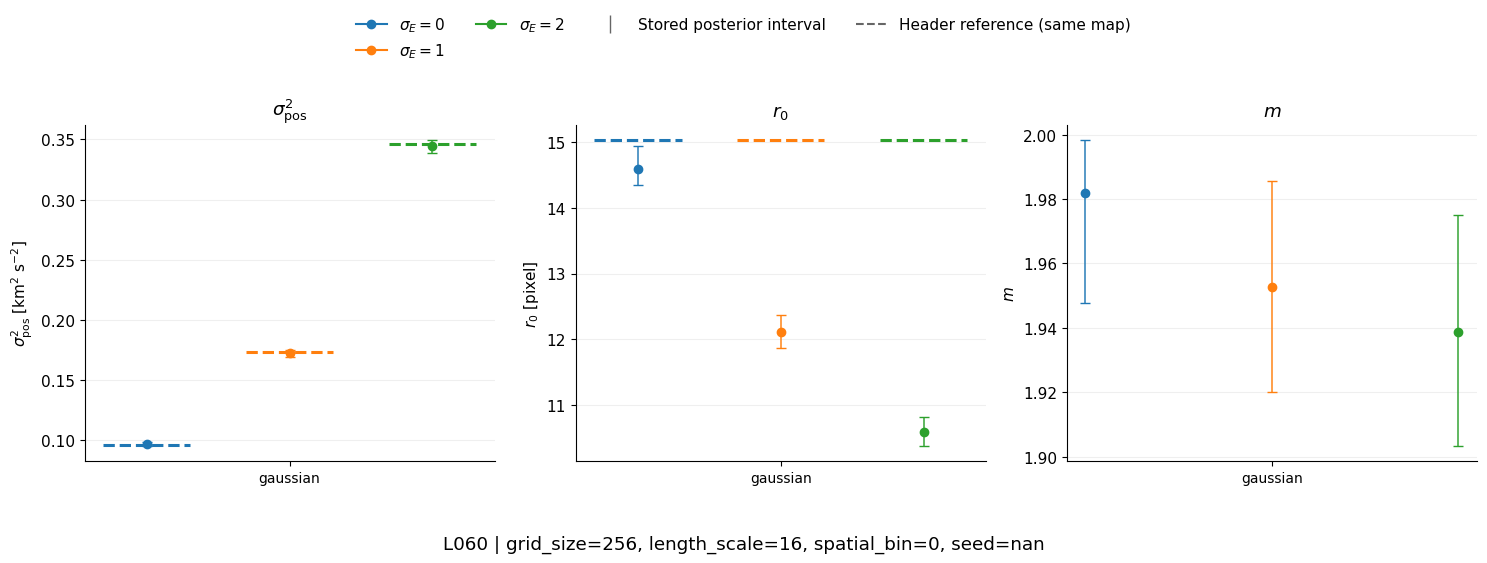

In [6]:
comparison = gv.select_fraction(results, COMPARISON_FRACTION)
comparison_tag = "baseline" if COMPARISON_FRACTION is None else f"L{round(100*COMPARISON_FRACTION):03d}"
if comparison.empty:
    print(f"No {comparison_tag} fits available. Choose a fraction listed in the coverage table.")
else:
    for batch_index, (batch_title, batch) in enumerate(gv.iter_batches(comparison)):
        fig, axes = gv.plot_parameters(
            batch, model_order=MODEL_ORDER, sigE_levels=SIGE_LEVELS,
            reference=SHOW_REFERENCES, labels=PARAM_LABELS, ylims=PARAM_YLIMS,
            title=f"{comparison_tag} | {batch_title}",
        )
        if SAVE_FIGURES:
            gv.save_figure(fig, FIGS_DIR, f"parameters_{comparison_tag}_{batch_index}_{batch_title}", formats=FIGURE_FORMATS)
        plt.show()
        plt.close(fig)

## 5. Inspect all Lfracc fits

Rows separate the covariance models (including stable alpha); the three columns show
`sig2`, `r0`, and `m`. Colors identify `sigE`, vertical segments show the stored posterior
intervals, and black rings mark the fractions selected in the configuration. Curves
connect available measurements only; inspect coverage for missing fractions.

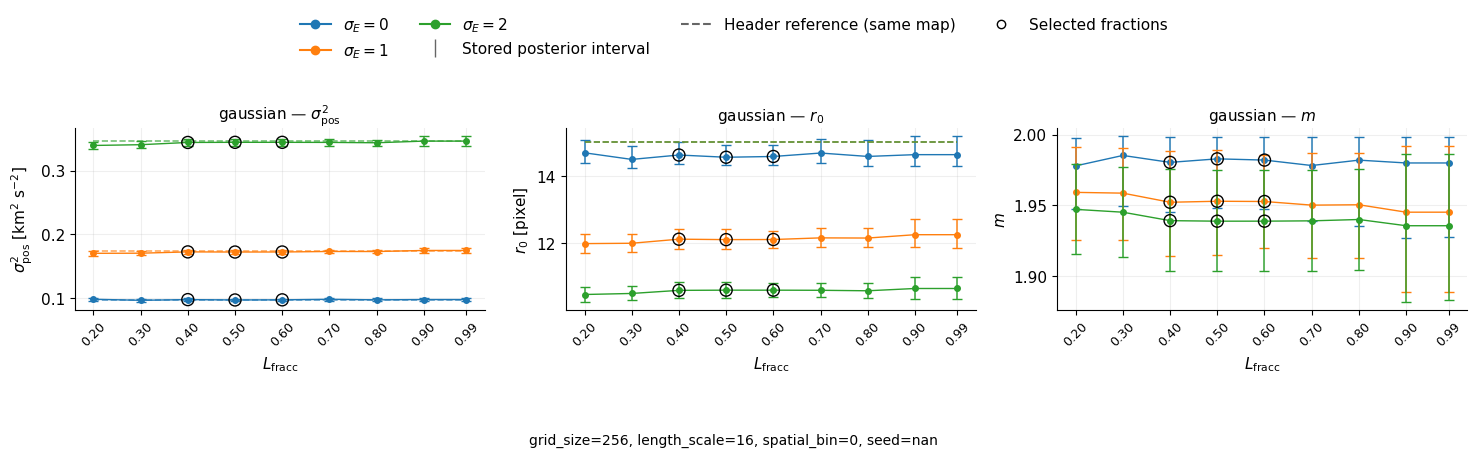

In [7]:
fraction_results = results.loc[results.fit_kind == "fraction"].copy()
if fraction_results.empty:
    print("No Lfracc files found. Baseline comparisons above are still available.")
else:
    for batch_index, (batch_title, batch) in enumerate(gv.iter_batches(fraction_results)):
        fig, axes = gv.plot_fraction_grid(
            batch, selected=SELECTED_FIT_LIMITS, selected_by_sample=SELECTED_BY_SAMPLE,
            model_order=MODEL_ORDER, sigE_levels=SIGE_LEVELS,
            reference=SHOW_REFERENCES, labels=PARAM_LABELS, ylims=PARAM_YLIMS,
            title=batch_title,
        )
        if SAVE_FIGURES:
            gv.save_figure(fig, FIGS_DIR, f"Lfracc_{batch_index}_{batch_title}", formats=FIGURE_FORMATS)
        plt.show()
        plt.close(fig)

## 6. Select fractions and inspect sensitivity

Choose one fraction to retain that result, or several for a **descriptive** arithmetic
mean of the fitted centers. The exported `fraction_std`, `value_min`, `value_max`, and
`relative_span` describe variation across fitting ranges. The summary interval is the
full envelope from the smallest lower endpoint to the largest upper endpoint.
It is **not** a combined credible interval or an uncertainty on the mean; these are
nested fits to the same data. No inverse-variance pooling is performed.

By default, a sample missing any requested fraction is omitted from the summary and
listed below. Set `REQUIRE_ALL_SELECTED=False` to allow a clearly reported partial
summary. If any selected interval is invalid, the summary center/scatter are retained
but its interval envelope is left missing.

In [8]:
selected_summary, selection_issues = gv.summarize_fractions(
    results, selected=SELECTED_FIT_LIMITS, by_sample=SELECTED_BY_SAMPLE,
    require_all=REQUIRE_ALL_SELECTED,
)
if not selection_issues.empty:
    display(selection_issues)
if selected_summary.empty:
    print("No selected summaries available. Review the selection and coverage.")
else:
    display(selected_summary[[
        "sample_id", "sigE", "parameter", "fit_limits_used", "n_fractions",
        "value", "interval_low", "interval_high", "fraction_std",
        "value_min", "value_max", "relative_span",
    ]])

,sample_id,sigE,parameter,fit_limits_used,n_fractions,value,interval_low,interval_high,fraction_std,value_min,value_max,relative_span
0,gaussian_moments_N256_L16_sigE0,0.0,m,"(0.4, 0.5, 0.6)",3,1.981729,1.945354,1.998580,0.001269,1.980353,1.982852,0.001261
1,gaussian_moments_N256_L16_sigE0,0.0,r0,"(0.4, 0.5, 0.6)",3,14.596525,14.320782,15.009766,0.033894,14.566512,14.633286,0.004575
2,gaussian_moments_N256_L16_sigE0,0.0,sig2,"(0.4, 0.5, 0.6)",3,0.097104,0.095083,0.099493,0.000285,0.096852,0.097413,0.005773
3,gaussian_moments_N256_L16_sigE1,1.0,m,"(0.4, 0.5, 0.6)",3,1.952584,1.914312,1.989042,0.000370,1.952168,1.952876,0.000363
4,gaussian_moments_N256_L16_sigE1,1.0,r0,"(0.4, 0.5, 0.6)",3,12.110654,11.828503,12.431525,0.007036,12.105107,12.118568,0.001111
5,gaussian_moments_N256_L16_sigE1,1.0,sig2,"(0.4, 0.5, 0.6)",3,0.172179,0.168886,0.175809,0.000118,0.172086,0.172313,0.001315
6,gaussian_moments_N256_L16_sigE2,2.0,m,"(0.4, 0.5, 0.6)",3,1.938920,1.903224,1.975426,0.000213,1.938790,1.939166,0.000194
7,gaussian_moments_N256_L16_sigE2,2.0,r0,"(0.4, 0.5, 0.6)",3,10.592610,10.365457,10.829424,0.003310,10.588790,10.594635,0.000552
8,gaussian_moments_N256_L16_sigE2,2.0,sig2,"(0.4, 0.5, 0.6)",3,0.344209,0.338321,0.349910,0.000125,0.344065,0.344286,0.000644


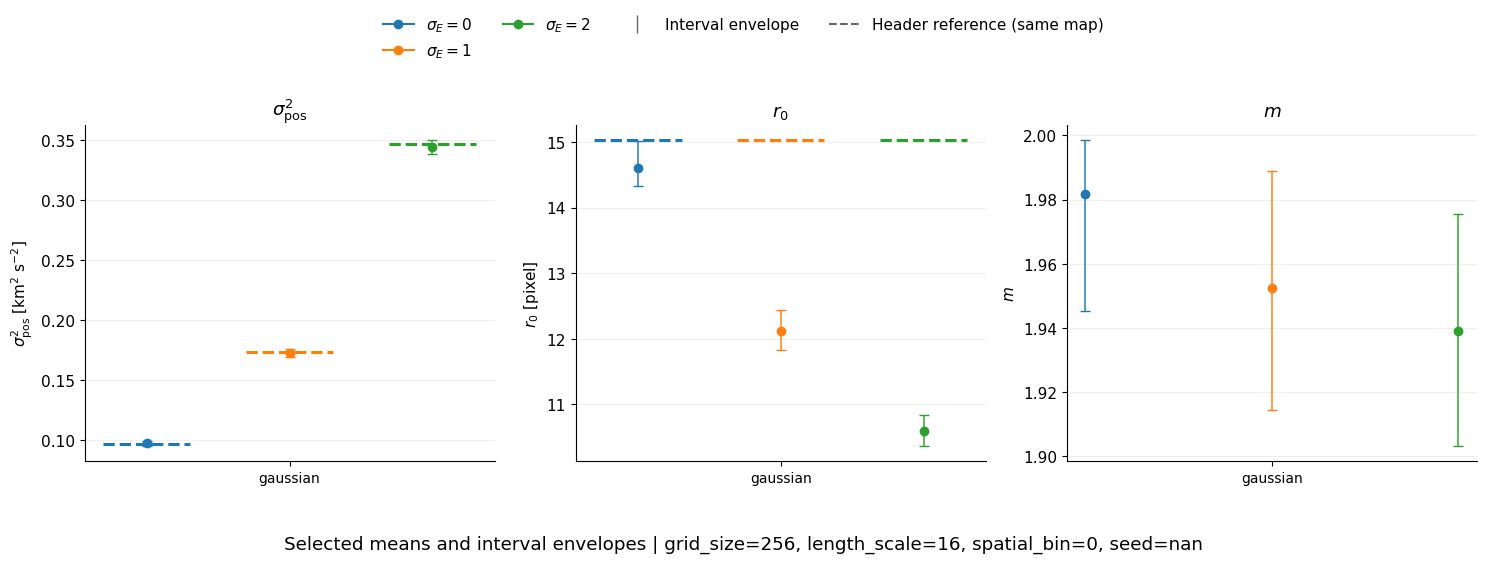

In [9]:
if not selected_summary.empty:
    for batch_index, (batch_title, batch) in enumerate(gv.iter_batches(selected_summary)):
        fig, axes = gv.plot_parameters(
            batch, model_order=MODEL_ORDER, sigE_levels=SIGE_LEVELS,
            reference=SHOW_REFERENCES, labels=PARAM_LABELS, ylims=PARAM_YLIMS,
            title=f"Selected means and interval envelopes | {batch_title}",
        )
        if SAVE_FIGURES:
            gv.save_figure(fig, FIGS_DIR, f"selected_parameters_{batch_index}_{batch_title}", formats=FIGURE_FORMATS)
        plt.show()
        plt.close(fig)

## 7. Overlay selected results on the fraction curves

Dotted horizontal lines show selected means. The faint bands show interval envelopes,
not an independent statistical combination of the fits.

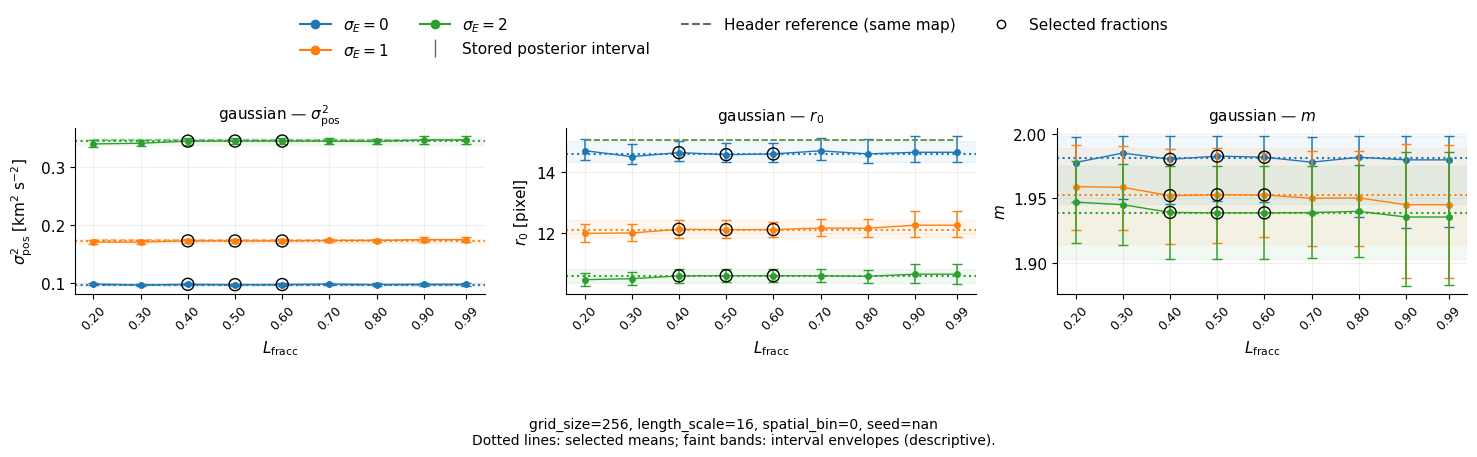

In [10]:
if not selected_summary.empty:
    for batch_index, (batch_title, batch) in enumerate(gv.iter_batches(fraction_results)):
        fig, axes = gv.plot_fraction_grid(
            batch, selected=SELECTED_FIT_LIMITS, selected_by_sample=SELECTED_BY_SAMPLE,
            summary=selected_summary, model_order=MODEL_ORDER, sigE_levels=SIGE_LEVELS,
            reference=SHOW_REFERENCES, labels=PARAM_LABELS, ylims=PARAM_YLIMS,
            title=batch_title,
        )
        if SAVE_FIGURES:
            gv.save_figure(fig, FIGS_DIR, f"Lfracc_selected_{batch_index}_{batch_title}", formats=FIGURE_FORMATS)
        plt.show()
        plt.close(fig)

## 8. Optional normalized comparison

Enable `MAKE_NORMALIZED_PLOTS` to compare fit/header-reference ratios. This is a
reference comparison only; decide whether each header quantity is physically the
appropriate reference before interpreting agreement with unity.

In [11]:
if MAKE_NORMALIZED_PLOTS and not comparison.empty:
    for batch_index, (batch_title, batch) in enumerate(gv.iter_batches(comparison)):
        fig, axes = gv.plot_parameters(
            batch, model_order=MODEL_ORDER, sigE_levels=SIGE_LEVELS,
            normalize=True, reference=True,
            title=f"{comparison_tag}: fit / header reference | {batch_title}",
        )
        if SAVE_FIGURES:
            gv.save_figure(fig, FIGS_DIR, f"normalized_{comparison_tag}_{batch_index}_{batch_title}", formats=FIGURE_FORMATS)
        plt.show()
        plt.close(fig)

## 9. Export tables

Exports retain the individual intervals, metadata, input filenames, and reference
values. The wide selected table has one row per sample. Statistical intervals and
fitting-range sensitivity are explicitly separate columns. Rerunning this cell updates
these derived tables, without changing the input FITS files.

In [12]:
TABLES_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(TABLES_DIR / "individual_fit_results.csv", index=False)
file_inventory.to_csv(TABLES_DIR / "fit_inventory.csv", index=False)
coverage.to_csv(TABLES_DIR / "fraction_coverage.csv")
load_issues.to_csv(TABLES_DIR / "load_issues.csv", index=False)
interval_review.to_csv(TABLES_DIR / "interval_review.csv", index=False)
selection_issues.to_csv(TABLES_DIR / "selection_issues.csv", index=False)

if not selected_summary.empty:
    selected_summary.to_csv(TABLES_DIR / "selected_results_long.csv", index=False)
    fields = ["value", "interval_low", "interval_high", "fraction_std", "value_min", "value_max", "relative_span"]
    wide = selected_summary.pivot(index="sample_id", columns="parameter", values=fields)
    wide.columns = [f"{param}_{field}" for field, param in wide.columns]
    metadata = selected_summary.drop_duplicates("sample_id").set_index("sample_id")[[
        "model_label", "sigE", *gv.BATCH_KEYS, "fit_limits_used", "n_fractions"
    ]]
    selected_wide = metadata.join(wide).reset_index()
    selected_wide.to_csv(TABLES_DIR / "selected_results_wide.csv", index=False)
    display(selected_wide)

print(f"Tables: {TABLES_DIR}")
print(f"Figures: {FIGS_DIR}")

,sample_id,model_label,sigE,grid_size,length_scale,spatial_bin,seed,fit_limits_used,n_fractions,m_value,...,sig2_fraction_std,m_value_min,r0_value_min,sig2_value_min,m_value_max,r0_value_max,sig2_value_max,m_relative_span,r0_relative_span,sig2_relative_span
0,gaussian_moments_N256_L16_sigE0,gaussian,0.0,256.0,16.0,0,NaN,"(0.4, 0.5, 0.6)",3,1.981729,...,0.000285,1.980353,14.566512,0.096852,1.982852,14.633286,0.097413,0.001261,0.004575,0.005773
1,gaussian_moments_N256_L16_sigE1,gaussian,1.0,256.0,16.0,0,NaN,"(0.4, 0.5, 0.6)",3,1.952584,...,0.000118,1.952168,12.105107,0.172086,1.952876,12.118568,0.172313,0.000363,0.001111,0.001315
2,gaussian_moments_N256_L16_sigE2,gaussian,2.0,256.0,16.0,0,NaN,"(0.4, 0.5, 0.6)",3,1.938920,...,0.000125,1.938790,10.588790,0.344065,1.939166,10.594635,0.344286,0.000194,0.000552,0.000644


Tables: C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\results_fit\visualization
Figures: C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\fit_results


In [13]:
# Default for samples without an explicit selection.
#SELECTED_FIT_LIMITS = (0.40, 0.50, 0.60)

# Examples: replace these keys with your exact sample_id values.
SELECTED_BY_SAMPLE = {
    "stable_alpha1.5_moments_N64_L16_sigE0": (0.30, 0.40, 0.50),
    "stable_alpha1.5_moments_N64_L16_sigE1": (0.40, 0.50, 0.60),
    "stable_alpha1.5_moments_N64_L16_sigE2": (0.50, 0.60, 0.70),
}

In [14]:
display(
    results[["sample_id", "model_label", "sigE"]]
    .drop_duplicates()
    .sort_values("sample_id")
)

,sample_id,model_label,sigE
81,gaussian_moments_N256_L16_sigE0,gaussian,0.0
108,gaussian_moments_N256_L16_sigE1,gaussian,1.0
135,gaussian_moments_N256_L16_sigE2,gaussian,2.0


In [15]:
# Catch misspelled sample IDs instead of silently using the default.
unknown_samples = set(SELECTED_BY_SAMPLE) - set(results["sample_id"])

if unknown_samples:
    raise ValueError(
        "These sample IDs are absent from the filtered results:\n"
        + "\n".join(sorted(unknown_samples))
    )

# Recalculate after changing the selections.
selected_summary, selection_issues = gv.summarize_fractions(
    results,
    selected=SELECTED_FIT_LIMITS,
    by_sample=SELECTED_BY_SAMPLE,
    require_all=REQUIRE_ALL_SELECTED,
)

if not selection_issues.empty:
    display(selection_issues)

if selected_summary.empty:
    print("No summaries available. Check the selected fractions and coverage.")

else:
    for batch_index, (batch_title, batch) in enumerate(
        gv.iter_batches(selected_summary)
    ):
        print(batch_title)

        # Show exactly which fractions contribute to each parameter.
        display(
            batch[[
                "sample_id",
                "parameter",
                "fit_limits_used",
                "n_fractions",
                "value",
                "interval_low",
                "interval_high",
            ]]
            .sort_values(["sample_id", "parameter"])
            .reset_index(drop=True)
        )

        fig, axes = gv.plot_parameters(
            batch,
            model_order=MODEL_ORDER,
            sigE_levels=SIGE_LEVELS,
            reference=SHOW_REFERENCES,
            labels=PARAM_LABELS,
            ylims=PARAM_YLIMS,
            title=f"Sample-specific Lfracc selections | {batch_title}",
        )

        if SAVE_FIGURES:
            gv.save_figure(
                fig,
                FIGS_DIR,
                f"selected_parameters_{batch_index}_{batch_title}",
                formats=FIGURE_FORMATS,
            )

        plt.show()
        plt.close(fig)

ValueError: These sample IDs are absent from the filtered results:
stable_alpha1.5_moments_N64_L16_sigE0
stable_alpha1.5_moments_N64_L16_sigE1
stable_alpha1.5_moments_N64_L16_sigE2